# Confusion Matrix — Tüm Modeller
## IEEE-CIS Fraud Detection

**Amaç:** Daha önce kaydedilen threshold tablolarından confusion matrix üretmek.
**Hiçbir model yeniden eğitilmez** — sadece CSV dosyaları okunur.

TP, FP, FN, TN değerleri threshold tablolarında zaten mevcut.

**İki eşik için confusion matrix üretilir:**
- F2-Optimal eşik (max F2 skoru)
- Recall ≥ 0.85 eşiği (operasyonel hedef, ulaşılabildiyse)

**Üretilen çıktılar:**
- Her model için ayrı PNG
- Tüm modelleri bir arada gösteren büyük karşılaştırma grafiği

## 1. Kütüphaneler ve Yollar

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['font.size'] = 10

from google.colab import drive
drive.mount('/content/drive')

# Threshold tablolarinin bulundugu klasor
RESULTS_DIR = '/content/drive/My Drive/Bitirme/04_Sonuclar/'
SAVE_DIR    = '/content/drive/My Drive/Bitirme/15-Mayıs-Cuma/'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f'Sonuc klasoru : {RESULTS_DIR}')
print('Kutuphaneler yuklendi.')

Mounted at /content/drive
Sonuc klasoru : /content/drive/My Drive/Bitirme/04_Sonuclar/
Kutuphaneler yuklendi.


## 2. Model Tanımları ve Threshold Tabloları

In [3]:
# Her model icin: (gorunen_ad, threshold_csv_dosyasi, renk)
MODELS = [
    {
        'name'     : 'LGB Optuna V2\n(Full Pipeline)',
        'short'    : 'LGB_Optuna_V2',
        'csv'      : RESULTS_DIR + 'lgb_optuna_v2_threshold_table.csv',
        'color'    : '#4CAF50',
        'ref_pr'   : 0.6307,
    },
    {
        'name'     : 'LGB Grid Search 256',
        'short'    : 'LGB_GS256',
        'csv'      : RESULTS_DIR + 'lgb_gs256_threshold_table.csv',
        'color'    : '#8BC34A',
        'ref_pr'   : 0.6288,
    },
    {
        'name'     : 'XGB Optuna',
        'short'    : 'XGB_Optuna',
        'csv'      : RESULTS_DIR + 'xgb_optuna_threshold_table.csv',
        'color'    : '#2196F3',
        'ref_pr'   : 0.6005,
    },
    {
        'name'     : 'XGB Grid Search 256',
        'short'    : 'XGB_GS256',
        'csv'      : RESULTS_DIR + 'xgb_gridsearch_threshold_table.csv',
        'color'    : '#03A9F4',
        'ref_pr'   : 0.5950,
    },
    {
        'name'     : 'Logistic Regression\nBaseline',
        'short'    : 'LR_Baseline',
        'csv'      : RESULTS_DIR + 'lr_baseline_threshold_table.csv',
        'color'    : '#FF9800',
        'ref_pr'   : 0.2607,
    },
    {
        'name'     : 'Ensemble St4\n(w_lgb=0.95)',
        'short'    : 'Ensemble_St4',
        'csv'      : RESULTS_DIR + 'ensemble_threshold_table.csv',
        'color'    : '#9C27B0',
        'ref_pr'   : 0.6256,
    },
    {
        'name'     : 'Ablation NoUID\n(+D Norm +Cat TE)',
        'short'    : 'Ablation_NoUID',
        'csv'      : RESULTS_DIR + 'lgb_ablation_nouid_threshold_table.csv',
        'color'    : '#FF5722',
        'ref_pr'   : 0.5109,
    },
    {
        'name'     : 'Ablation RawOnly\n(Ham Ozellikler)',
        'short'    : 'Ablation_Raw',
        'csv'      : RESULTS_DIR + 'lgb_ablation_raw_threshold_table.csv',
        'color'    : '#795548',
        'ref_pr'   : 0.5207,
    },
]

# Mevcut dosyalari kontrol et
print('Threshold tablosu dosya kontrolu:')
for m in MODELS:
    exists = os.path.exists(m['csv'])
    status = 'BULUNDU ✓' if exists else 'YOK — dosya eksik!'
    print(f'  {m["short"]:<25}: {status}')
    m['available'] = exists

Threshold tablosu dosya kontrolu:
  LGB_Optuna_V2            : BULUNDU ✓
  LGB_GS256                : BULUNDU ✓
  XGB_Optuna               : BULUNDU ✓
  XGB_GS256                : BULUNDU ✓
  LR_Baseline              : BULUNDU ✓
  Ensemble_St4             : BULUNDU ✓
  Ablation_NoUID           : BULUNDU ✓
  Ablation_Raw             : BULUNDU ✓


## 3. Threshold Tablolarını Yükle ve F2-Optimal / Recall>=85% Noktaları Bul

In [4]:
TOTAL_TEST = 118108  # y_test.shape[0] — sabit

def load_critical_points(csv_path):
    """Threshold tablosundan F2-optimal ve Recall>=85% satirlarini dondurur."""
    df = pd.read_csv(csv_path)

    # Sutun adlarini normalize et
    col_map = {}
    for col in df.columns:
        cl = col.lower()
        if 'esik' in cl or 'threshold' in cl: col_map[col] = 'Esik'
        elif cl == 'recall':                   col_map[col] = 'Recall'
        elif 'precision' in cl or cl == 'prec': col_map[col] = 'Precision'
        elif cl == 'f2':                        col_map[col] = 'F2'
        elif cl == 'f1':                        col_map[col] = 'F1'
        elif cl == 'tp':                        col_map[col] = 'TP'
        elif cl == 'fp':                        col_map[col] = 'FP'
        elif cl == 'fn':                        col_map[col] = 'FN'
        elif cl == 'tn':                        col_map[col] = 'TN'
    df = df.rename(columns=col_map)

    # TN yoksa hesapla
    if 'TN' not in df.columns:
        df['TN'] = TOTAL_TEST - df['TP'] - df['FP'] - df['FN']

    f2_opt = df.sort_values('F2', ascending=False).iloc[0]
    mask_r85 = df['Recall'] >= 0.85
    r85 = df[mask_r85].sort_values('Precision', ascending=False).iloc[0] if mask_r85.any() else None
    max_rec = df.sort_values('Recall', ascending=False).iloc[0]

    return df, f2_opt, r85, max_rec


# Yukle
print('Yükleme sonuçları:')
print(f'{"Model":<25} {"F2-Opt Esik":>12} {"F2-Opt F2":>10} {"R85 Esik":>10} {"R85 Prec":>10}')
print('-' * 72)
for m in MODELS:
    if not m['available']:
        print(f'{m["short"]:<25} --- dosya eksik ---')
        m['df'] = None; m['f2_opt'] = None; m['r85'] = None; m['max_rec'] = None
        continue
    df, f2_opt, r85, max_rec = load_critical_points(m['csv'])
    m['df'] = df; m['f2_opt'] = f2_opt; m['r85'] = r85; m['max_rec'] = max_rec
    r85_esik = f"{r85['Esik']:.3f}" if r85 is not None else 'YOK'
    r85_prec = f"{r85['Precision']:.4f}" if r85 is not None else 'YOK'
    print(f'{m["short"]:<25} {f2_opt["Esik"]:>12.3f} {f2_opt["F2"]:>10.4f} {r85_esik:>10} {r85_prec:>10}')

Yükleme sonuçları:
Model                      F2-Opt Esik  F2-Opt F2   R85 Esik   R85 Prec
------------------------------------------------------------------------
LGB_Optuna_V2                    0.010     0.5914        YOK        YOK
LGB_GS256                        0.010     0.5898        YOK        YOK
XGB_Optuna                       0.300     0.5756      0.005     0.1000
XGB_GS256                        0.450     0.5722      0.010     0.1164
LR_Baseline                      0.850     0.4340      0.150     0.0787
Ensemble_St4                     0.030     0.5950        YOK        YOK
Ablation_NoUID                   0.010     0.5235        YOK        YOK
Ablation_Raw                     0.005     0.5261        YOK        YOK


## 4. Confusion Matrix Çizim Fonksiyonu

In [5]:
def draw_cm_from_counts(ax, tp, fp, fn, tn, threshold, title, color='Blues'):
    """
    TP, FP, FN, TN sayilarindan confusion matrix cizer.
    Model yeniden calistirmaya gerek yok.
    """
    tp, fp, fn, tn = int(tp), int(fp), int(fn), int(tn)
    total = tp + fp + fn + tn

    cm_arr = np.array([[tn, fp], [fn, tp]])

    labels = np.array([
        [f'TN\n{tn:,}\n({tn/total*100:.1f}%)', f'FP\n{fp:,}\n({fp/total*100:.1f}%)'],
        [f'FN\n{fn:,}\n({fn/total*100:.1f}%)', f'TP\n{tp:,}\n({tp/total*100:.1f}%)']
    ])

    prec = tp / (tp + fp + 1e-10)
    rec  = tp / (tp + fn + 1e-10)
    f2   = 5 * prec * rec / (4 * prec + rec + 1e-10)

    sns.heatmap(
        cm_arr, annot=labels, fmt='', cmap=color,
        xticklabels=['Normal', 'Fraud'],
        yticklabels=['Normal', 'Fraud'],
        ax=ax, cbar=False, linewidths=1.5, linecolor='white',
        annot_kws={'size': 9},
    )
    ax.set_title(
        f'{title}\nEşik:{threshold:.3f} | R:{rec:.3f} | P:{prec:.3f} | F2:{f2:.3f}',
        fontsize=9, fontweight='bold'
    )
    ax.set_xlabel('Tahmin', fontsize=9)
    ax.set_ylabel('Gerçek', fontsize=9)
    ax.tick_params(labelsize=8)
    return prec, rec, f2

print('Confusion matrix fonksiyonu hazir.')

Confusion matrix fonksiyonu hazir.


## 5. Her Model İçin Ayrı Confusion Matrix (F2-Optimal)

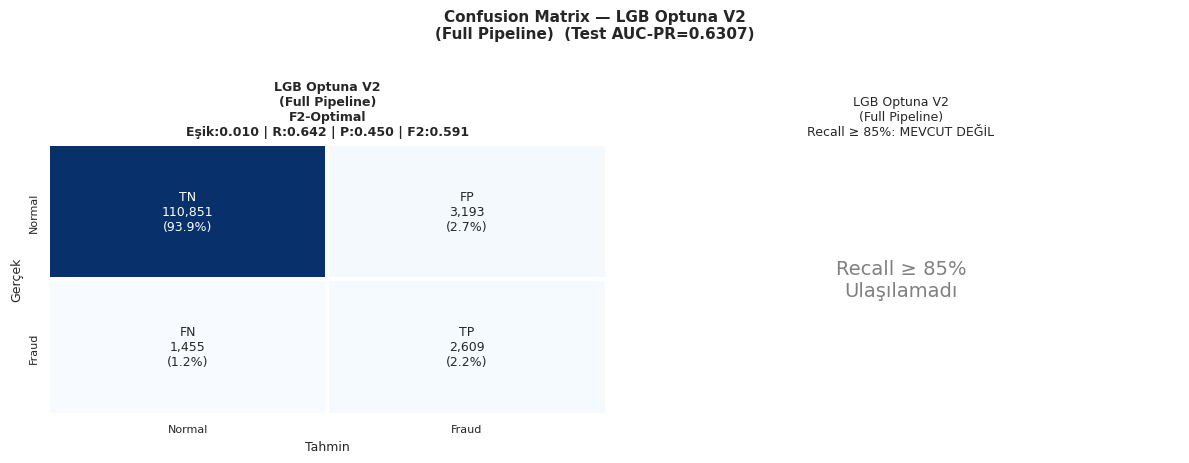

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_LGB_Optuna_V2.png


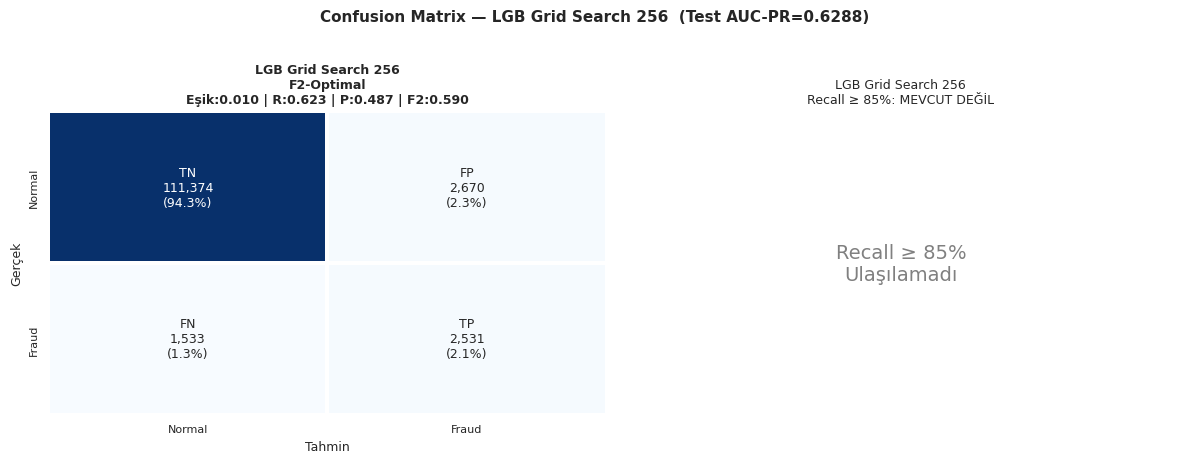

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_LGB_GS256.png


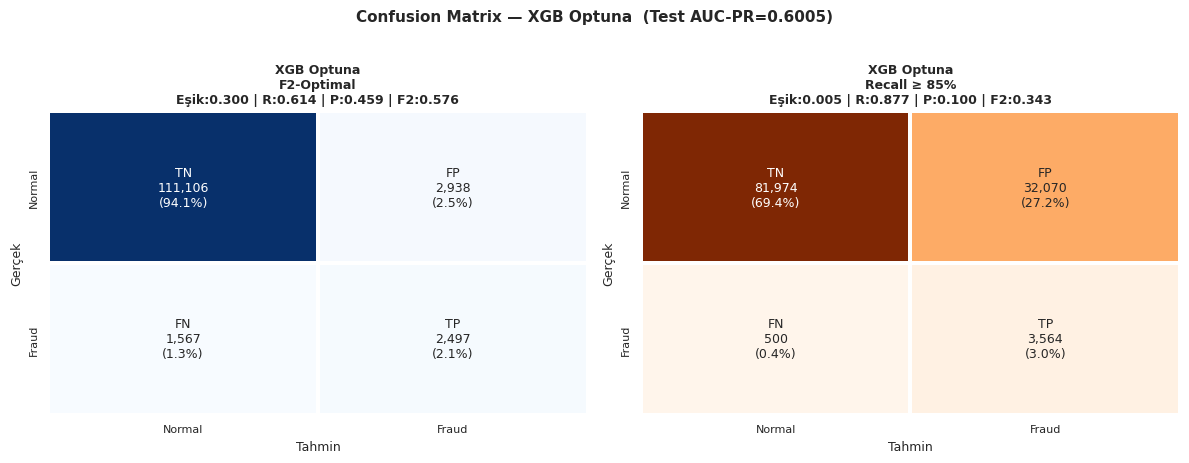

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_XGB_Optuna.png


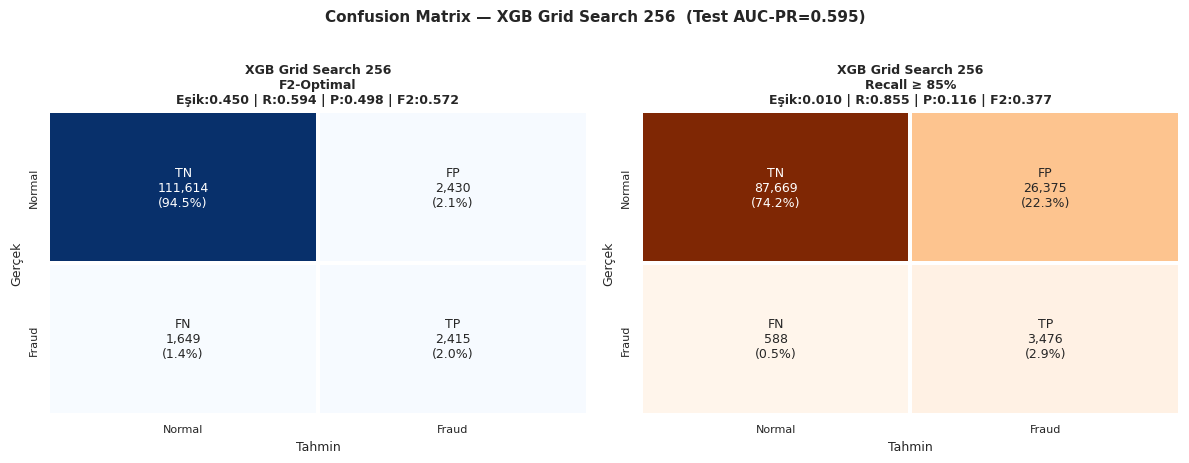

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_XGB_GS256.png


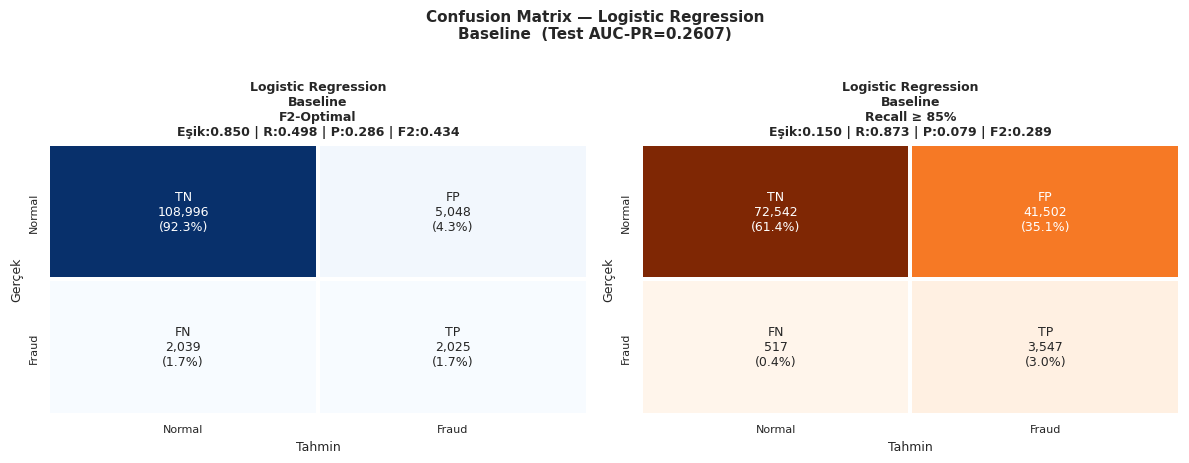

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_LR_Baseline.png


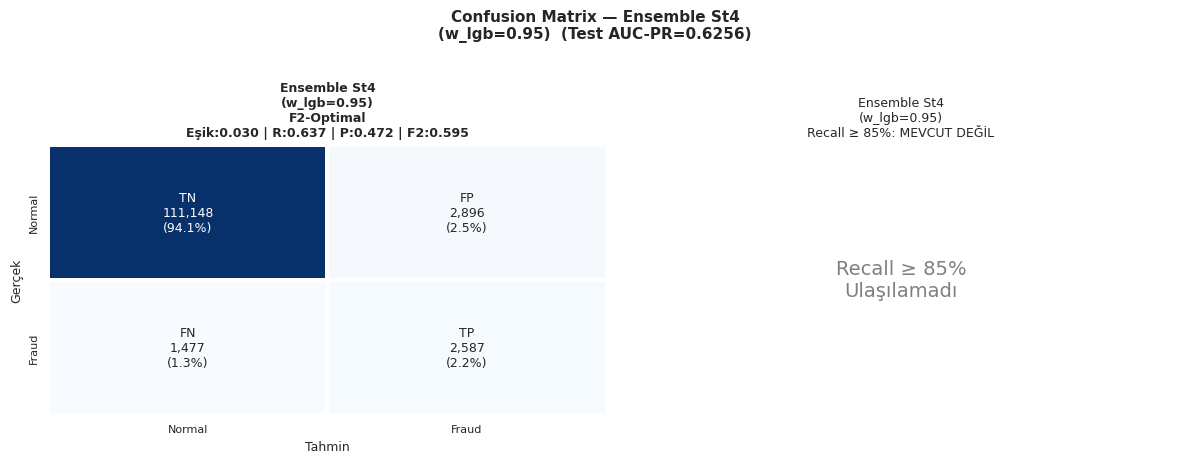

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_Ensemble_St4.png


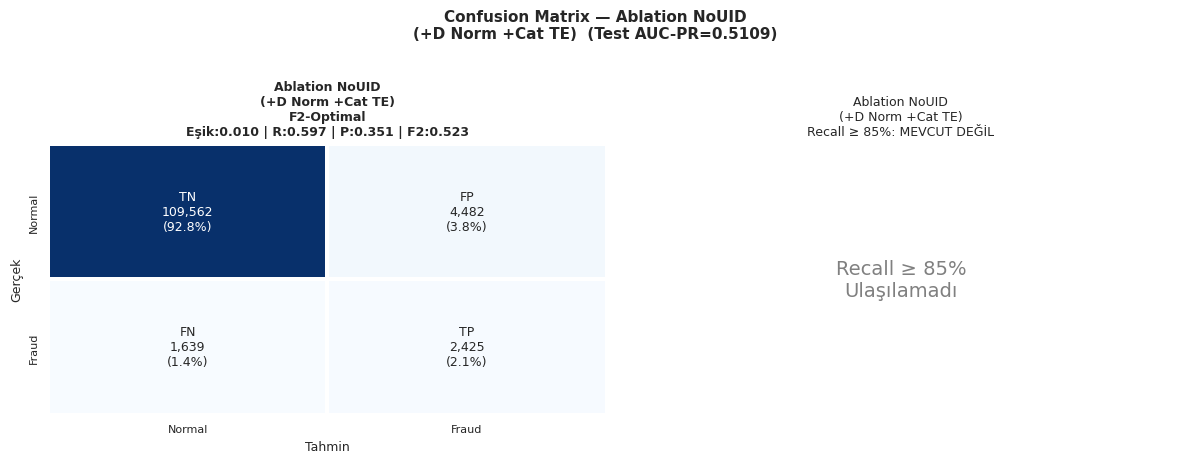

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_Ablation_NoUID.png


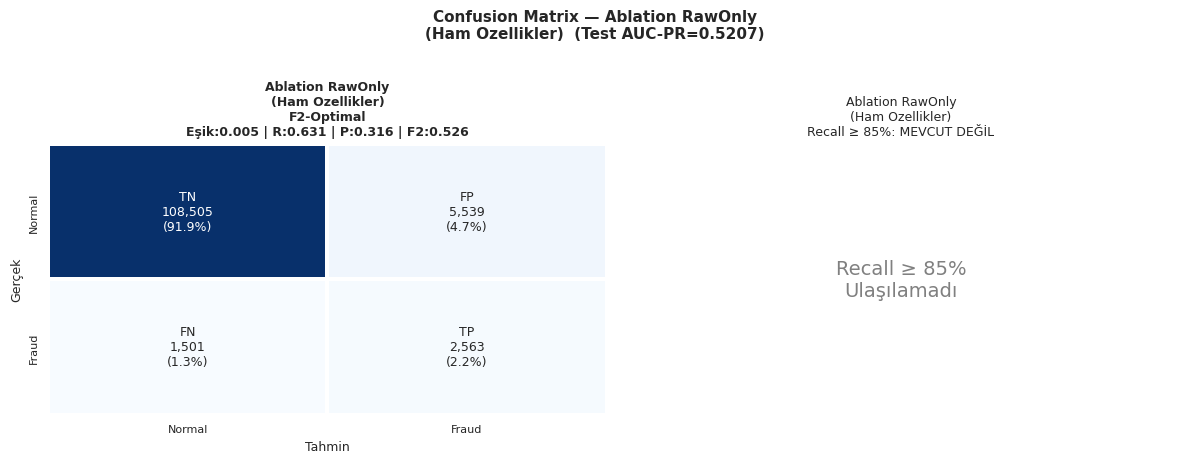

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_Ablation_Raw.png

Toplam 8 confusion matrix kaydedildi.


In [6]:
saved_files = []

for m in MODELS:
    if m['f2_opt'] is None:
        print(f'[ATLANDI] {m["short"]} — veri yok')
        continue

    row = m['f2_opt']

    # TN kontrolu — bazi tablolarda TN olmayabilir
    if 'TN' in row.index and not pd.isna(row['TN']):
        tn_val = row['TN']
    else:
        # TN = toplam - TP - FP - FN
        # Toplam test ornegi: y_test.shape[0] = 118108
        TOTAL_TEST = 118108
        tn_val = TOTAL_TEST - int(row['TP']) - int(row['FP']) - int(row['FN'])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Sol: F2-optimal
    draw_cm_from_counts(
        axes[0],
        tp=row['TP'], fp=row['FP'], fn=row['FN'], tn=tn_val,
        threshold=row['Esik'],
        title=f'{m["name"]}\nF2-Optimal',
        color='Blues'
    )

    # Sag: Recall>=85% (varsa)
    if m['r85'] is not None:
        r85_row = m['r85']
        if 'TN' in r85_row.index and not pd.isna(r85_row['TN']):
            tn_r85 = r85_row['TN']
        else:
            tn_r85 = TOTAL_TEST - int(r85_row['TP']) - int(r85_row['FP']) - int(r85_row['FN'])
        draw_cm_from_counts(
            axes[1],
            tp=r85_row['TP'], fp=r85_row['FP'], fn=r85_row['FN'], tn=tn_r85,
            threshold=r85_row['Esik'],
            title=f'{m["name"]}\nRecall ≥ 85%',
            color='Oranges'
        )
    else:
        axes[1].text(0.5, 0.5, 'Recall ≥ 85%\nUlaşılamadı',
                     ha='center', va='center', transform=axes[1].transAxes,
                     fontsize=14, color='gray')
        axes[1].set_title(f'{m["name"]}\nRecall ≥ 85%: MEVCUT DEĞİL', fontsize=9)
        axes[1].axis('off')

    plt.suptitle(f'Confusion Matrix — {m["name"]}  (Test AUC-PR={m["ref_pr"]})',
                 fontsize=11, fontweight='bold', y=1.02)
    plt.tight_layout()

    save_path = SAVE_DIR + f'cm_{m["short"]}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    saved_files.append(save_path)
    print(f'Kaydedildi: {save_path}')

print(f'\nToplam {len(saved_files)} confusion matrix kaydedildi.')

## 6. Tüm Modeller — Büyük Karşılaştırma Grafiği (F2-Optimal)

Tek bir figürde tüm mevcut modellerin F2-optimal confusion matrixleri.

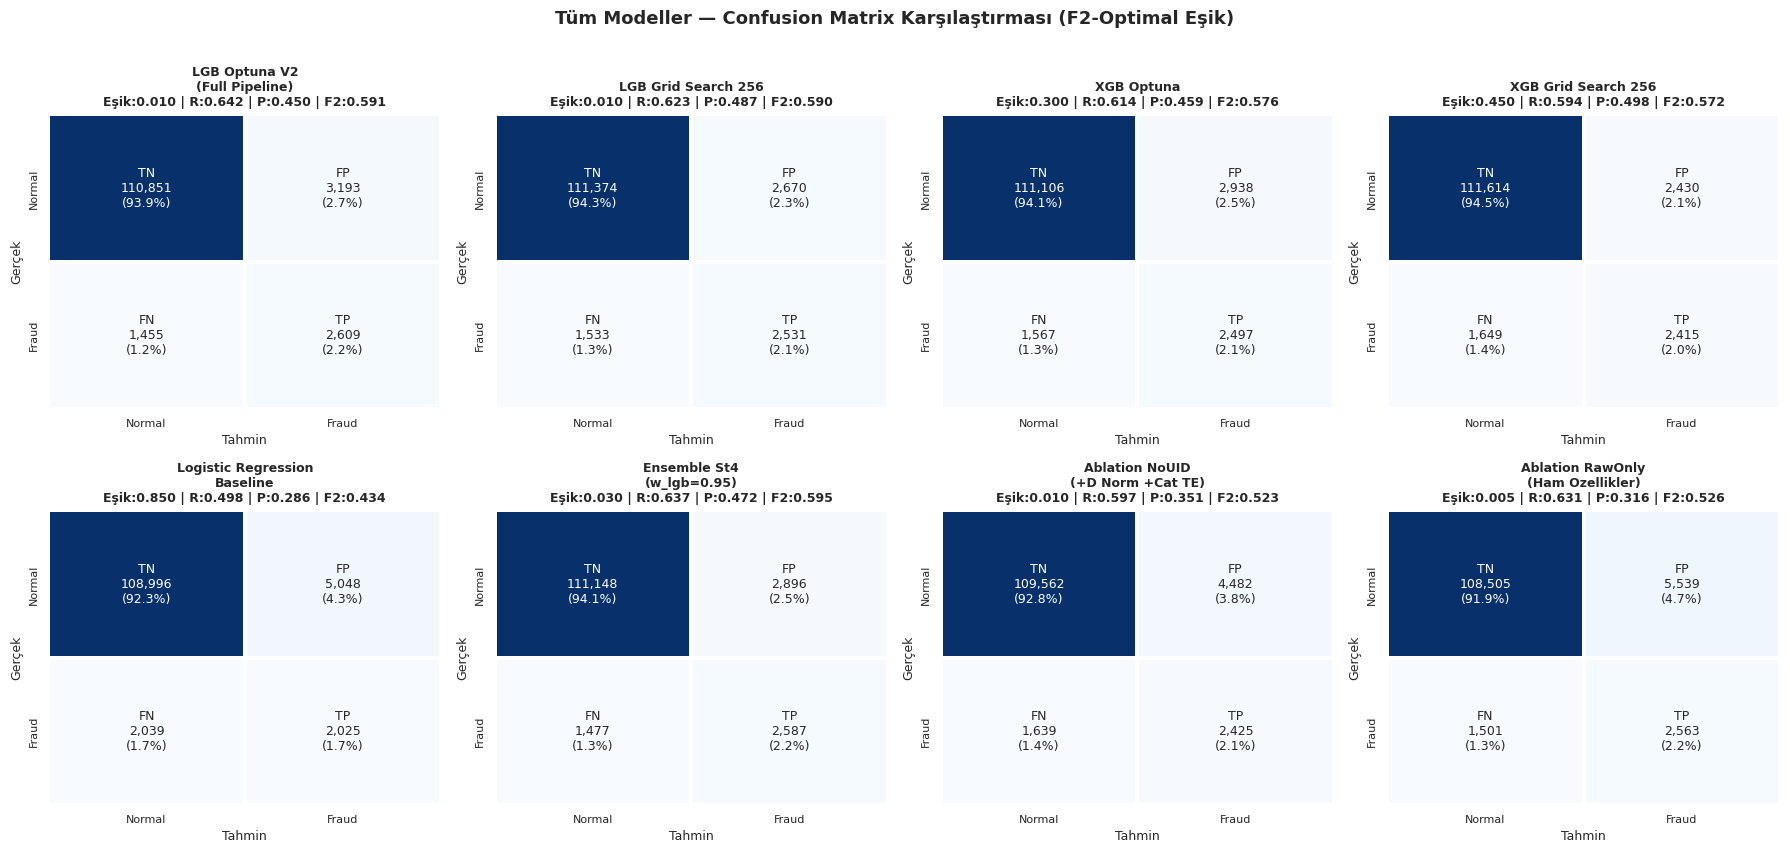

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_all_models_f2opt.png


In [7]:
available_models = [m for m in MODELS if m['f2_opt'] is not None]
n = len(available_models)

if n == 0:
    print('Hic model yok!')
else:
    # Izgara boyutu: max 4 sutun
    ncols = min(4, n)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4.2))

    # axes'i her zaman 2D yap
    if n == 1:
        axes = np.array([[axes]])
    elif nrows == 1:
        axes = axes.reshape(1, -1)

    TOTAL_TEST = 118108

    for idx, m in enumerate(available_models):
        row_idx = idx // ncols
        col_idx = idx % ncols
        ax = axes[row_idx][col_idx]

        f2_row = m['f2_opt']
        if 'TN' in f2_row.index and not pd.isna(f2_row['TN']):
            tn_val = f2_row['TN']
        else:
            tn_val = TOTAL_TEST - int(f2_row['TP']) - int(f2_row['FP']) - int(f2_row['FN'])

        draw_cm_from_counts(
            ax,
            tp=f2_row['TP'], fp=f2_row['FP'], fn=f2_row['FN'], tn=tn_val,
            threshold=f2_row['Esik'],
            title=m['name'],
            color='Blues'
        )

    # Bos eksenleri gizle
    for idx in range(n, nrows * ncols):
        row_idx = idx // ncols
        col_idx = idx % ncols
        axes[row_idx][col_idx].axis('off')

    plt.suptitle(
        'Tüm Modeller — Confusion Matrix Karşılaştırması (F2-Optimal Eşik)',
        fontsize=13, fontweight='bold', y=1.01
    )
    plt.tight_layout()
    grid_path = SAVE_DIR + 'cm_all_models_f2opt.png'
    plt.savefig(grid_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Kaydedildi: {grid_path}')

## 7. Özet Tablo — Tüm Modeller F2-Optimal Metrikleri

In [8]:
TOTAL_TEST = 118108

summary_rows = []
print('ABLATION + MODEL KARSILASTIRMA TABLOSU (F2-Optimal Esik)')
print('=' * 90)
print(f'{"Model":<30} {"AUC-PR":>8} {"Esik":>7} {"Recall":>7} {"Prec":>7} {"F2":>7} {"TP":>6} {"FP":>7} {"FN":>6}')
print('-' * 90)

for m in MODELS:
    if m['f2_opt'] is None:
        print(f'{m["short"]:<30} --- henuz calistirilmadi ---')
        continue

    row = m['f2_opt']
    if 'TN' in row.index and not pd.isna(row['TN']):
        tn_val = int(row['TN'])
    else:
        tn_val = TOTAL_TEST - int(row['TP']) - int(row['FP']) - int(row['FN'])

    tp, fp, fn = int(row['TP']), int(row['FP']), int(row['FN'])
    prec = tp / (tp + fp + 1e-10)
    rec  = tp / (tp + fn + 1e-10)
    f2   = 5 * prec * rec / (4 * prec + rec + 1e-10)
    pr   = m['ref_pr'] if m['ref_pr'] is not None else float('nan')

    print(f'{m["short"]:<30} {pr:>8.4f} {row["Esik"]:>7.3f} {rec:>7.4f} {prec:>7.4f} {f2:>7.4f} {tp:>6,} {fp:>7,} {fn:>6,}')

    summary_rows.append({
        'model'       : m['short'],
        'test_auc_pr' : pr,
        'f2opt_threshold': row['Esik'],
        'f2opt_recall'   : round(rec, 4),
        'f2opt_precision': round(prec, 4),
        'f2opt_f2'       : round(f2, 4),
        'f2opt_tp'       : tp,
        'f2opt_fp'       : fp,
        'f2opt_fn'       : fn,
        'f2opt_tn'       : tn_val,
        'recall85_reached': m['r85'] is not None,
        'r85_precision'  : round(m['r85']['Precision'], 4) if m['r85'] is not None else None,
    })

print('=' * 90)

# CSV olarak kaydet
if summary_rows:
    df_summary = pd.DataFrame(summary_rows)
    summary_csv = SAVE_DIR + 'all_models_cm_summary.csv'
    df_summary.to_csv(summary_csv, index=False)
    print(f'\nOzet CSV kaydedildi: {summary_csv}')

ABLATION + MODEL KARSILASTIRMA TABLOSU (F2-Optimal Esik)
Model                            AUC-PR    Esik  Recall    Prec      F2     TP      FP     FN
------------------------------------------------------------------------------------------
LGB_Optuna_V2                    0.6307   0.010  0.6420  0.4497  0.5914  2,609   3,193  1,455
LGB_GS256                        0.6288   0.010  0.6228  0.4866  0.5898  2,531   2,670  1,533
XGB_Optuna                       0.6005   0.300  0.6144  0.4594  0.5756  2,497   2,938  1,567
XGB_GS256                        0.5950   0.450  0.5942  0.4985  0.5722  2,415   2,430  1,649
LR_Baseline                      0.2607   0.850  0.4983  0.2863  0.4340  2,025   5,048  2,039
Ensemble_St4                     0.6256   0.030  0.6366  0.4718  0.5950  2,587   2,896  1,477
Ablation_NoUID                   0.5109   0.010  0.5967  0.3511  0.5235  2,425   4,482  1,639
Ablation_Raw                     0.5207   0.005  0.6307  0.3163  0.5261  2,563   5,539  1,501

Ozet 

## 8. Tamamlandı

In [9]:
print('=' * 60)
print('  Confusion Matrix Notebook Tamamlandi')
print('=' * 60)
print()
print('Kaydedilen dosyalar:')
for f in saved_files:
    print(f'  {f}')
print(f'  {SAVE_DIR}cm_all_models_f2opt.png')
print(f'  {SAVE_DIR}all_models_cm_summary.csv')
print()
print('NOT: Ablation notebooklari calistirildiktan sonra')
print('bu notebook tekrar calistirilirsa ablation confusion')
print('matrixleri de otomatik olarak eklenir.')
print('=' * 60)

  Confusion Matrix Notebook Tamamlandi

Kaydedilen dosyalar:
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_LGB_Optuna_V2.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_LGB_GS256.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_XGB_Optuna.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_XGB_GS256.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_LR_Baseline.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_Ensemble_St4.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_Ablation_NoUID.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_Ablation_Raw.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/cm_all_models_f2opt.png
  /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/all_models_cm_summary.csv

NOT: Ablation notebooklari calistirildiktan sonra
bu notebook tekrar calistirilirsa ablation confusion
matrixleri de otomatik olarak eklenir.
